![Imgur](https://i.imgur.com/h4PPC71.png)
#**18-modul. Amaliyot. Customer Churn**
# 18.6. Modul boʻyicha yakuniy amaliy vazifa

**Bu vazifa orqali data sayns jarayoni:**

✔️ maʼlumot tayyorlash;

  ✔️ model qurish;

  ✔️ baholash;

  ✔️ natijalarni tahlil qilish
  kabi koʻnikmalarga ega boʻlasiz.

#**Vazifa: bank mijozlarining noroziligini bashorat qilish**

**Vazifa tavsifi**

Sizga bank mijozlari haqida maʼlumotlar toʻplami berilgan. Maqsad – qaysi mijozlar bank xizmatlaridan voz kechishini (churn) oldindan bashorat qilish. Bank bu orqali oʻz mijozlarini ushlab qolish strategiyalarini yaxshilashi mumkin.

**Maʼlumotlar toʻplami**

Kaggle platformasidagi Churn Modelling maʼlumotlar toʻplamidan foydalanamiz. Ushbu toʻplamda 10 000 ta mijozning quyidagi maʼlumotlari mavjud:

- mijoz identifikatori (RowNumber, CustomerId, Surname);
- geografik joylashuvi (Geography);
- jinsi (Gender);
- yoshi (Age);
- kredit balli (CreditScore);
- yillik daromadi (EstimatedSalary);
- bankda qancha vaqtdan beri mijoz ekani (Tenure);
- qancha mahsulotdan foydalanishi (NumOfProducts);
- faoliyati (HasCrCard, IsActiveMember);
- balans (Balance);
- prognoz qilish holati, churn (Exited) – maqsadli oʻzgaruvchi.

**Topshiriqlar**

1. **Maʼlumotlarni tahlil qilish va tozalash:**
   - Maʼlumotlardagi boʻsh qiymatlar va anomaliyalarni aniqlang hamda tozalang.
   - Kategorik oʻzgaruvchilarni raqamli koʻrinishga oʻtkazing (masalan, one-hot encoding yordamida).

2. **Maʼlumotlarni boʻlish:**
   - Maʼlumotlarni training va test toʻplamlariga ajrating (masalan, 80% training, 20% test).

3. **Model qurish:**
   - Quyidagi algoritmlar yordamida modellarni yarating:
     - Logistic Regression
     - Support Vector Machine (SVM)
     - Decision Tree
     - Random Forest
     - XGBoost

4. **Modellarni baholash:**
   - Har bir model uchun quyidagi koʻrsatkichlarni hisoblang:
     - Aniqlik (Accuracy)
     - Toʻgʻrilik (Precision)
     - Recall
     - F1-score

5. **Natijalarni tahlil qilish:**
   - Olingan natijalarni solishtiring va qaysi model eng yaxshi ishlashini aniqlang.
   - Eng yaxshi model asosida bankka mijozlarni ushlab qolish boʻyicha tavsiyalar bering.
---

###*** ESLATMA**. *Ushbu amaliy vazifada siz oʻtmagan mavzulardan ham savollar va vazifalar boʻlishi mumkin! Bu savollarni mustaqil oʻrganishingiz kerak boʻladi. Bunday vazifalar mustaqil izlanish koʻnikmangizni oshirish uchun tayyorlandi!*

In [185]:
import pandas as pd
import numpy as np
import sklearn

url = "https://raw.githubusercontent.com/alishermutalov/praktikum-datasets/refs/heads/praktikum/Churn_Modelling.xls"
df = pd.read_csv(url, index_col='RowNumber')
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1


In [186]:
# Javobni shu yerda yozing.
df.reset_index(drop=True, inplace=True)
df


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [187]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  object 
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  object 
 4   Gender           10000 non-null  object 
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB


In [188]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [189]:
df = df[df["EstimatedSalary"]>=600]
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [190]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,9.970000e+03,9970.000000,9970.000000,9970.00000,9970.000000,9970.000000,9970.000000,9970.000000,9970.000000,9970.000000
mean,1.569100e+07,650.523069,38.921565,5.01013,76513.088749,1.530291,0.705316,0.515145,100390.402907,0.203511
std,7.195487e+04,96.699680,10.493915,2.89097,62406.041659,0.581880,0.455923,0.499796,57335.628420,0.402629
min,1.556570e+07,350.000000,18.000000,0.00000,0.000000,1.000000,0.000000,0.000000,600.360000,0.000000
25%,1.562854e+07,584.000000,32.000000,3.00000,0.000000,1.000000,0.000000,0.000000,51539.777500,0.000000
50%,1.569091e+07,652.000000,37.000000,5.00000,97221.520000,1.000000,1.000000,1.000000,100502.325000,0.000000
75%,1.575334e+07,718.000000,44.000000,7.00000,127671.965000,2.000000,1.000000,1.000000,149473.800000,0.000000
max,1.581569e+07,850.000000,92.000000,10.00000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


In [191]:
df.reset_index(drop=True, inplace=True)
df

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9965,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9966,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9967,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9968,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


Bizning datamizda hech qanday NaN qiymatlar mavjud emas ekan.Shu bilan birga hech qanday ma'lumot turlari bilan bog'liq muammo yo'q va anomaliya qiymat sifatida EstimatedSalary ustunidagi yillik daromadi 600 dollardan kamlarini tashlab yubordim

In [192]:
df.Geography.value_counts()

,count
Geography,
France,4996
Germany,2500
Spain,2474


Biz CustomerId, Surname ustunlarini tashlab yuboramiz sababi bu ustunlar bizni natijamizga hech qanday ta'sir ko'rsatmaydi.

In [193]:
df = df.drop(["CustomerId","Surname"], axis=1)
df

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...
9965,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9966,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9967,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9968,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [194]:
df1 = df[["CreditScore","Age","Tenure","Balance","NumOfProducts","HasCrCard","IsActiveMember","EstimatedSalary","Exited"]]
df1

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,42,2,0.00,1,1,1,101348.88,1
1,608,41,1,83807.86,1,0,1,112542.58,0
2,502,42,8,159660.80,3,1,0,113931.57,1
3,699,39,1,0.00,2,0,0,93826.63,0
4,850,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...
9965,771,39,5,0.00,2,1,0,96270.64,0
9966,516,35,10,57369.61,1,1,1,101699.77,0
9967,709,36,7,0.00,1,0,1,42085.58,1
9968,772,42,3,75075.31,2,1,0,92888.52,1


In [195]:
df1.corrwith(df1["Exited"])

,0
CreditScore,-0.026953
Age,0.285280
Tenure,-0.014871
Balance,0.118501
NumOfProducts,-0.047509
HasCrCard,-0.006604
IsActiveMember,-0.155143
EstimatedSalary,0.012997
Exited,1.000000


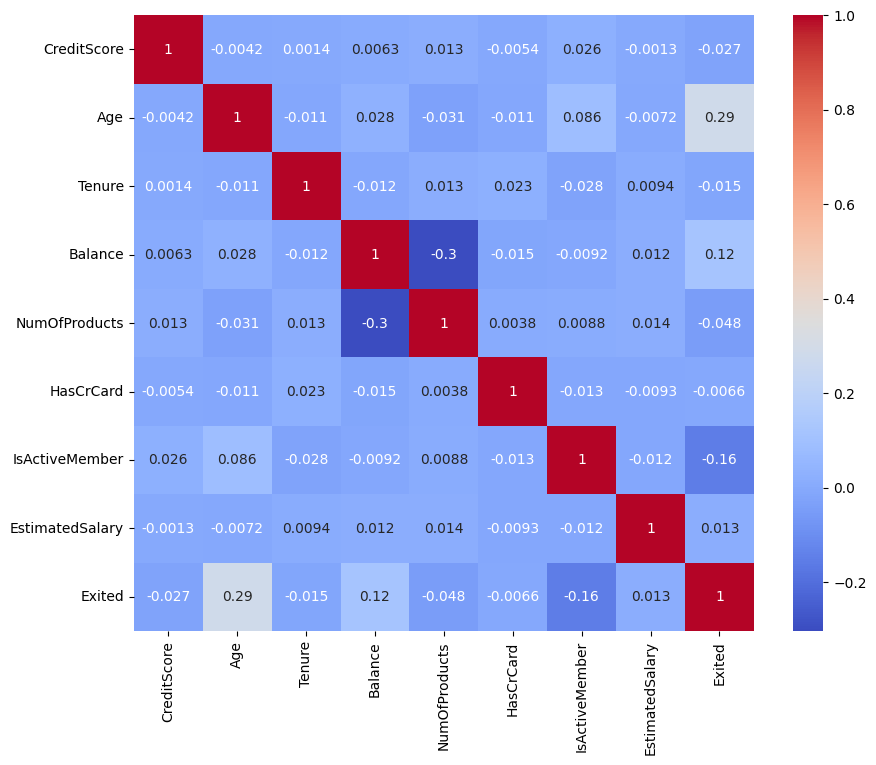

In [196]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(df1.corr(), annot=True, cmap='coolwarm')
plt.show()

In [197]:
X = df.drop("Exited", axis=1)
y = df["Exited"]

In [198]:
X.Gender.value_counts()

,count
Gender,
Male,5443
Female,4527


In [199]:
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(X, X["Gender"]):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

/tmp/ipython-input-1075774925.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_train, x='Gender', palette='viridis')


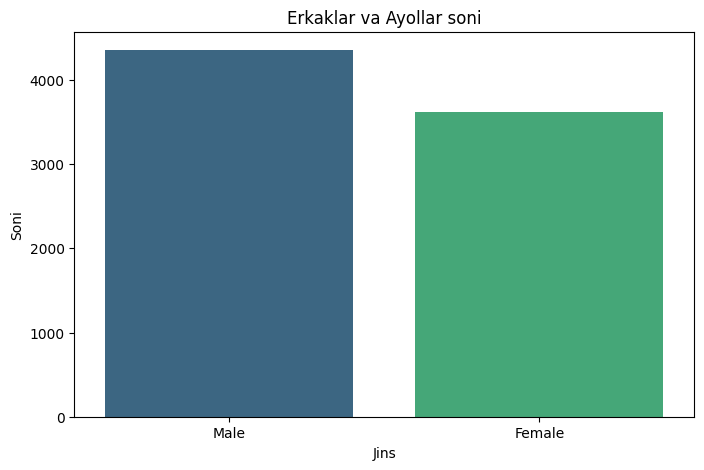

In [200]:
plt.figure(figsize=(8, 5))
sns.countplot(data=X_train, x='Gender', palette='viridis')
plt.title('Erkaklar va Ayollar soni')
plt.xlabel('Jins')
plt.ylabel('Soni')
plt.show()

/tmp/ipython-input-641298475.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=X_test, x='Gender', palette='viridis')


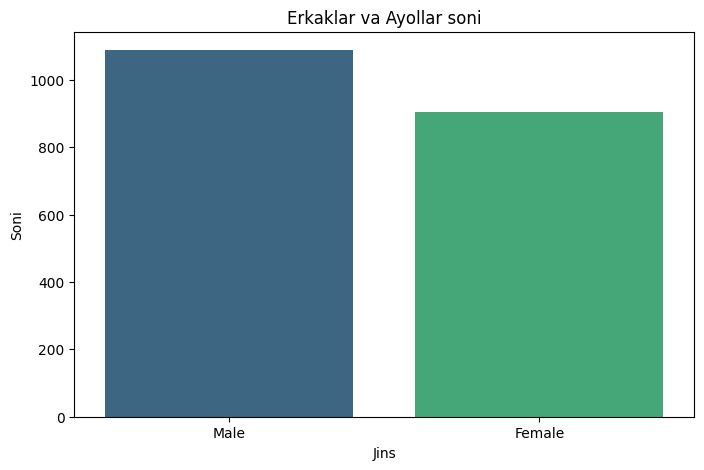

In [201]:
plt.figure(figsize=(8, 5))
sns.countplot(data=X_test, x='Gender', palette='viridis')
plt.title('Erkaklar va Ayollar soni')
plt.xlabel('Jins')
plt.ylabel('Soni')
plt.show()

In [202]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import jaccard_score, confusion_matrix, classification_report, roc_curve

In [203]:
num_data = X_train.drop(["Geography","Gender"], axis=1)
cat_data = X_train[["Geography","Gender"]]

In [204]:
num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])
cat_pipeline = Pipeline([
    ("encoder", OneHotEncoder())
])

In [205]:
num_col = list(num_data.columns)
cat_col = ["Geography","Gender"]

In [206]:
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_col),
    ("cat", cat_pipeline, cat_col)
])

In [208]:
X_train_prepared = full_pipeline.fit_transform(X_train)
X_train_prepared

array([[-6.59441687e-01, -3.68958188e-01, -5.65605515e-04, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       [ 1.58413091e-01,  1.34380377e+00, -5.65605515e-04, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       [ 8.59449457e-02,  3.72263983e+00, -1.04162782e+00, ...,
         1.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       ...,
       [-6.80146871e-01, -3.68958188e-01, -1.04162782e+00, ...,
         0.00000000e+00,  1.00000000e+00,  0.00000000e+00],
       [ 7.27805657e-01,  2.01962465e-01, -1.04162782e+00, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       [-1.39447573e+00,  1.05834345e+00,  6.93475870e-01, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

In [209]:
log_reg = LogisticRegression(class_weight='balanced')
log_reg.fit(X_train_prepared, y_train)

LogisticRegression(class_weight='balanced')

In [211]:
svm = SVC(class_weight='balanced', probability=True)
svm.fit(X_train_prepared, y_train)

SVC(class_weight='balanced', probability=True)

In [212]:
dt = DecisionTreeClassifier()
dt.fit(X_train_prepared, y_train)

DecisionTreeClassifier()

In [213]:
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100)
rf.fit(X_train_prepared, y_train)

RandomForestClassifier(class_weight='balanced')

In [214]:
xg = XGBClassifier(scale_pos_weight=4)
xg.fit(X_train_prepared, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [215]:
X_test_prepared = full_pipeline.transform(X_test)
X_test_prepared[:3]

array([[ 0.31370197,  0.77288312,  1.38751735,  0.32774372, -0.90659577,
         0.6490302 ,  0.97572093, -1.71529245,  1.        ,  0.        ,
         0.        ,  0.        ,  1.        ],
       [-0.1211069 ,  3.62748639,  0.34645513,  0.06923599,  0.80488538,
         0.6490302 ,  0.97572093, -0.77734597,  1.        ,  0.        ,
         0.        ,  0.        ,  1.        ],
       [ 1.86659079, -0.46411163, -1.04162782, -1.23036982,  0.80488538,
        -1.54076035, -1.02488321,  1.14555607,  1.        ,  0.        ,
         0.        ,  1.        ,  0.        ]])

In [216]:
y_log_reg = log_reg.predict(X_test_prepared)
y_log_reg

array([0, 1, 0, ..., 0, 0, 0])

In [217]:
y_svm = svm.predict(X_test_prepared)
y_svm

array([1, 0, 0, ..., 0, 0, 0])

In [218]:
y_dt = dt.predict(X_test_prepared)
y_dt

array([1, 0, 0, ..., 1, 1, 0])

In [219]:
y_rf = rf.predict(X_test_prepared)
y_rf

array([0, 0, 0, ..., 0, 0, 0])

In [220]:
y_xg = xg.predict(X_test_prepared)
y_xg

array([0, 0, 0, ..., 0, 0, 0])

In [221]:
print("Logistic regression:",jaccard_score(y_test, y_log_reg))
print("SVC:",jaccard_score(y_test, y_svm))
print("Decision tree:",jaccard_score(y_test, y_dt))
print("Random forest:",jaccard_score(y_test, y_rf))
print("XGBoost:",jaccard_score(y_test, y_xg))


Logistic regression: 0.32109004739336494
SVC: 0.4152542372881356
Decision tree: 0.3480392156862745
Random forest: 0.3839479392624729
XGBoost: 0.419672131147541


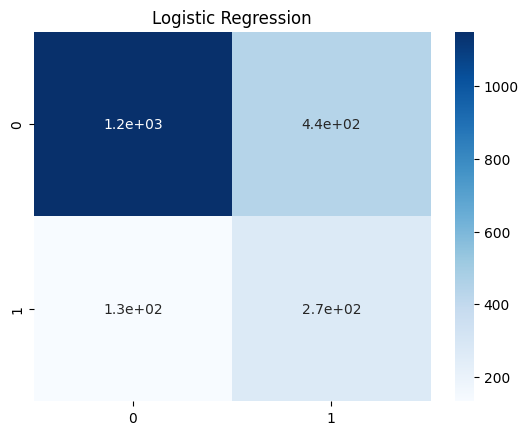

Logistic Regressor
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1590
           1       0.38      0.67      0.49       404

    accuracy                           0.71      1994
   macro avg       0.64      0.70      0.64      1994
weighted avg       0.79      0.71      0.74      1994



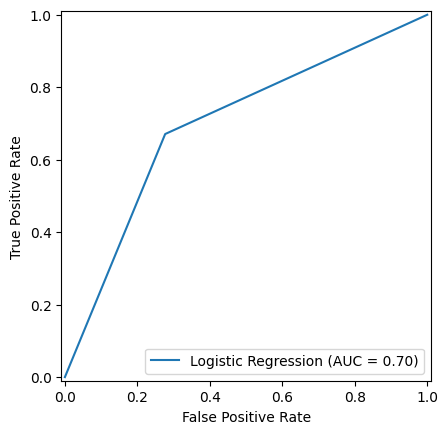

In [237]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay
sns.heatmap(confusion_matrix(y_test, y_log_reg), annot=True, cmap='Blues')
plt.title('Logistic Regression')
plt.show()


fpr, tpr, thresholds = roc_curve(y_test, y_log_reg)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Logistic Regression')
display.plot()


print(f"Logistic Regressor\n{classification_report(y_test, y_log_reg)}")

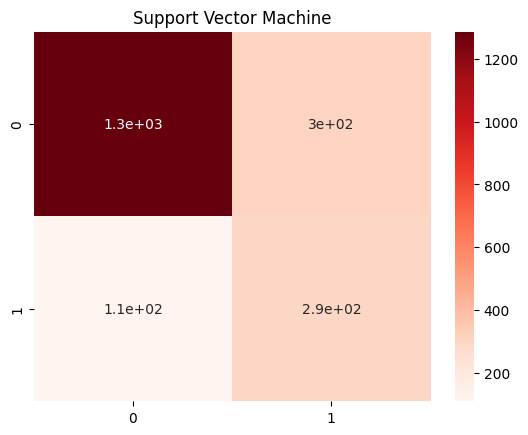

Support Vector Machine
              precision    recall  f1-score   support

           0       0.92      0.81      0.86      1590
           1       0.49      0.73      0.59       404

    accuracy                           0.79      1994
   macro avg       0.71      0.77      0.72      1994
weighted avg       0.83      0.79      0.81      1994



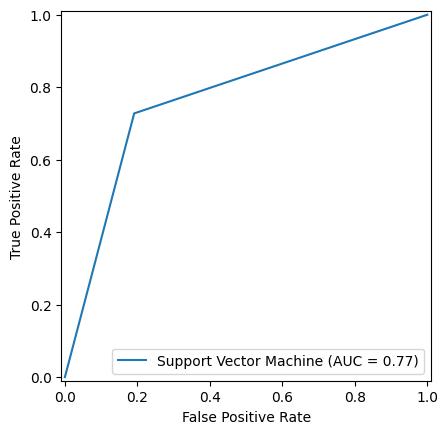

In [242]:
sns.heatmap(confusion_matrix(y_test, y_svm), annot=True, cmap='Reds')
plt.title('Support Vector Machine')
plt.show()

print(f"Support Vector Machine\n{classification_report(y_test, y_svm)}")

fpr, tpr, thresholds = roc_curve(y_test, y_svm)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Support Vector Machine')
display.plot()



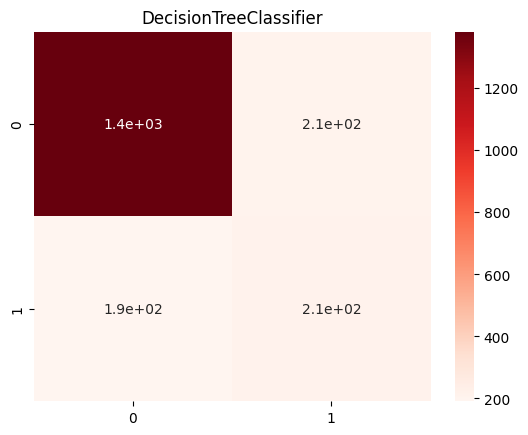

DecisionTreeClassifier
              precision    recall  f1-score   support

           0       0.88      0.87      0.87      1590
           1       0.51      0.53      0.52       404

    accuracy                           0.80      1994
   macro avg       0.69      0.70      0.70      1994
weighted avg       0.80      0.80      0.80      1994



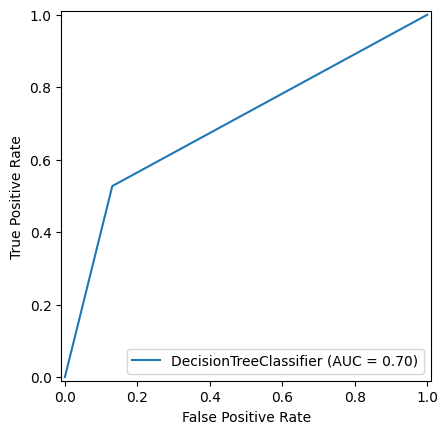

In [243]:
sns.heatmap(confusion_matrix(y_test, y_dt), annot=True, cmap='Reds')
plt.title('DecisionTreeClassifier')
plt.show()

print(f"DecisionTreeClassifier\n{classification_report(y_test, y_dt)}")

fpr, tpr, thresholds = roc_curve(y_test, y_dt)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='DecisionTreeClassifier')
display.plot()

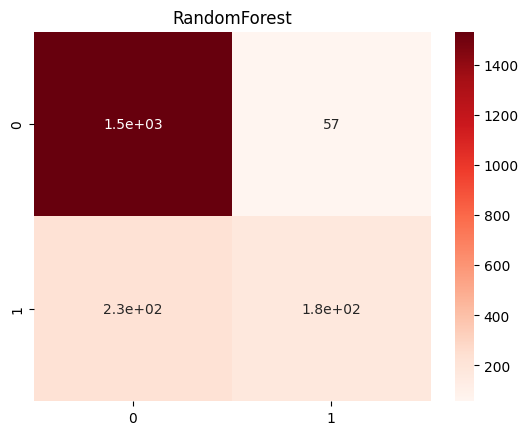

RandomForestClassifier
              precision    recall  f1-score   support

           0       0.87      0.96      0.92      1590
           1       0.76      0.44      0.55       404

    accuracy                           0.86      1994
   macro avg       0.81      0.70      0.74      1994
weighted avg       0.85      0.86      0.84      1994



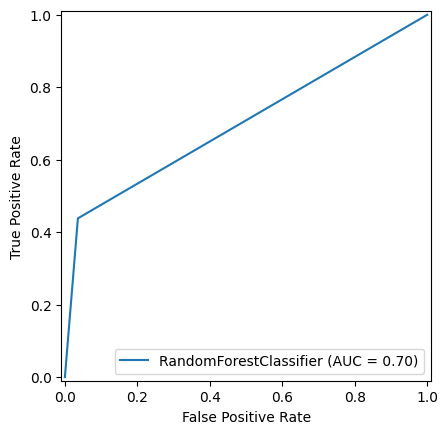

In [244]:
sns.heatmap(confusion_matrix(y_test, y_rf), annot=True, cmap='Reds')
plt.title('RandomForest')
plt.show()

print(f"RandomForestClassifier\n{classification_report(y_test, y_rf)}")

fpr, tpr, thresholds = roc_curve(y_test, y_rf)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='RandomForestClassifier')
display.plot()

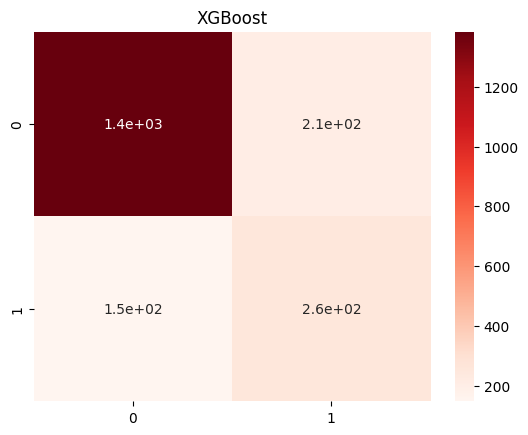

XGBoost
              precision    recall  f1-score   support

           0       0.90      0.87      0.89      1590
           1       0.55      0.63      0.59       404

    accuracy                           0.82      1994
   macro avg       0.73      0.75      0.74      1994
weighted avg       0.83      0.82      0.83      1994



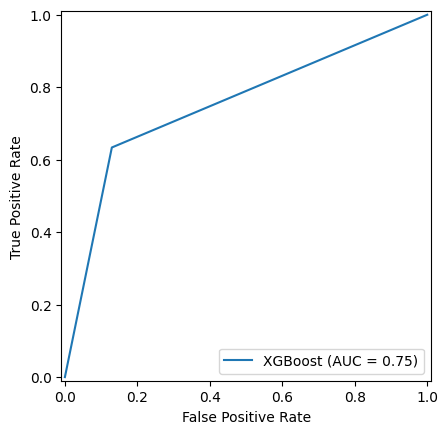

In [245]:
sns.heatmap(confusion_matrix(y_test, y_xg), annot=True, cmap='Reds')
plt.title('XGBoost')
plt.show()

print(f"XGBoost\n{classification_report(y_test, y_xg)}")

fpr, tpr, thresholds = roc_curve(y_test, y_xg)
roc_auc = auc(fpr, tpr)
display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='XGBoost')
display.plot()


Yuqoridagi solishtirishlarga ko'ra, bizning Support Vector Machine, XGBoost qolgan modellarga nisbatan yaxshi natija ko'rsatdi.